# v15c — position-relative analysis

## The claim under test

v14's per-context 10%-FPR thresholds spanned **0.000132 to 0.994230**. If a payload is a
*localised* disturbance, then a within-document statistic like `max(D) − median(D)` should be
comparable across contexts where the absolute score is not.

## Four experiments

| # | Question | Decides |
|---|---|---|
| 1 | **Ablation**: v14 last-token features vs v15 chunk features vs both | does position help at all, on the same folds and classifier |
| 2 | **Threshold comparability** | does the per-context threshold spread collapse? this is the actual fix |
| 3 | **Localisation** | does the flagged chunk contain the payload? ground truth from `span_start` |
| 4 | **Indirect LOCO** | train BIPIA → test InjecAgent and back. A payload-shaped delta should be family-invariant |

Exp 3 is the one that cannot be faked by a better classifier: if the argmax chunk lands on the
payload well above chance, the detector is doing what the thesis says it does.

## Two tiers of negative, never pooled

`*-Clean` (payload slot removed / declarative filler) and `*-HardNeg` (benign **imperative**
filler at the same position) are reported separately. A false positive on tier 1 is a bug; a
false positive on tier 2 is a design question about where the trust boundary sits.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")

SEED, N_THRESH, FPR_BUDGET = 42, 400, 0.10
TARGET_ASR, TARGET_FPR = 5.0, 10.0
PCA_DIMS, N_SPLITS = 512, 5

def make_hgb():   # v14 run 2: the head that matters
    return HistGradientBoostingClassifier(max_iter=300, random_state=SEED)
def make_logreg():
    return LogisticRegression(class_weight="balanced", max_iter=5000, C=10.0,
                              solver="lbfgs", random_state=SEED)
PRIMARY = make_hgb
RESULT_DIR, FIG = "results/v15", "mslsamv15"
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs("outputs", exist_ok=True)

CACHE = "representation_cache/chunked_v15"
man   = json.load(open(f"{CACHE}/manifest.json"))
LAYERS, MC = man["layers"], man["max_chunks"]
MIN_CHUNK_TOK = man["min_chunk_tok"]
MIN_CHUNKS = man["min_chunks"]
rows_df = pd.read_csv(f"{CACHE}/rows.csv").reset_index(drop=True)
assert man["rows"] == len(rows_df)

SH  = sorted(f for f in os.listdir(CACHE) if f.startswith("shard_"))
IDX = [np.load(f"{CACHE}/{f}")["row_idx"] for f in SH]

def load_layer(li):
    X = np.zeros((len(rows_df), MC, 4096), np.float16)
    for f, idx in zip(SH, IDX):
        X[idx] = np.load(f"{CACHE}/{f}")[f"layer_{li}"]
    return X

NCH = rows_df.n_chunks.values.astype(int)
is_base = (rows_df.corpus == "Baseline-Dolly").values
ev_mask = ~is_base
ev = rows_df[ev_mask].reset_index(drop=True)
ev_rows = np.where(ev_mask)[0]
print(rows_df.groupby(["corpus","label"]).size().unstack(fill_value=0).to_string())
print(f"\nevaluation rows {len(ev):,} | baseline {is_base.sum():,}"
      f" | chunking {man['chunking']}, <={MC} positions, >={MIN_CHUNK_TOK} tok each")
print("chunks per row by corpus:")
print(rows_df.groupby("corpus").n_chunks.agg(["median","min","max"]).to_string())

label                 0     1
corpus                       
BIPIA                 0  1200
BIPIA-Clean         480     0
BIPIA-HardNeg       481     0
Baseline-Dolly      400     0
InjecAgent            0   186
InjecAgent-Clean    479     0
InjecAgent-HardNeg  509     0

evaluation rows 3,335 | baseline 400 | chunking proportional, <=16 positions, >=8 tok each
chunks per row by corpus:
                    median  min  max
corpus                              
BIPIA                 16.0   14   16
BIPIA-Clean           16.0   13   16
BIPIA-HardNeg         16.0   14   16
Baseline-Dolly         6.0    5   16
InjecAgent            16.0   10   16
InjecAgent-Clean      16.0   10   16
InjecAgent-HardNeg    16.0   11   16


In [2]:
# ---- PCA in CHUNK space, then first differences -----------------------------
# The basis is fitted on Dolly chunk states, NOT on v14's last-token basis: a mid-document
# state is not distributed like an end-of-prompt state, and reusing the old basis would
# quietly under-represent exactly the variance v15 is trying to read.
PC, DL, MU, CINV = {}, {}, {}, {}
for li in LAYERS:
    X = load_layer(li)                                  # (N, MC, 4096) fp16
    flat_base = X[is_base].reshape(-1, 4096).astype(np.float32)
    keep = np.repeat(np.arange(MC)[None, :], is_base.sum(), 0) < NCH[is_base][:, None]
    flat_base = flat_base[keep.reshape(-1)]             # valid chunks only
    N_PCA = min(PCA_DIMS, flat_base.shape[0] - 1, 4096)
    p = PCA(n_components=N_PCA).fit(flat_base)
    Z = p.transform(X.reshape(-1, 4096).astype(np.float32)).reshape(len(rows_df), MC, N_PCA)
    PC[li] = Z[ev_rows].astype(np.float32)
    MU[li] = p.transform(flat_base).mean(0)          # baseline mean IN PCA space
    # First differences isolate each segment's contribution, because a causal model's
    # state at segment k already contains segments 1..k.
    #
    # np.diff alone gives MC-1 deltas for MC segments, so segment 0 has none -- and
    # BIPIA places the payload at the START half the time. Mapping those to delta 0
    # would silently point at segment 1 (an off-by-one that would have shown up as
    # ~50% localisation failure looking like "the method does not work").
    # So segment 0's delta is its state relative to the baseline mean -- the step from
    # "no content" to "segment 0" -- and deltas align 1:1 with segments.
    d0 = PC[li][:, 0:1, :] - MU[li][None, None, :]
    D = np.concatenate([d0, np.diff(PC[li], axis=1)], axis=1)   # (n_ev, MC, N_PCA)
    DL[li] = D
    cov = np.cov(p.transform(flat_base).T) + np.eye(N_PCA) * 1e-4
    CINV[li] = np.linalg.inv(cov)
    del X, Z, flat_base
NCH_EV = NCH[ev_rows]
print(f"PCA {N_PCA} comps/layer on {int(is_base.sum())} baseline rows "
      f"({int((np.arange(MC)[None,:] < NCH[is_base][:,None]).sum()):,} chunk states)")

def valid_delta_mask(n_chunks):
    # deltas now align 1:1 with segments, so D_k exists for k = 0..n_chunks-1
    return np.arange(MC)[None, :] < n_chunks[:, None]

PCA 512 comps/layer on 400 baseline rows (2,789 chunk states)


In [3]:
# ---- per-chunk scalars, then order statistics -------------------------------
def _norm(A): return A / (np.linalg.norm(A, axis=-1, keepdims=True) + 1e-8)

def payload_chunk(rows):
    # Ground-truth segment index of the payload, from span_start. Chunks are spaced
    # proportionally over each row's tokens, so the segment is simply the payload's
    # RELATIVE position times that row's chunk count -- no token arithmetic needed,
    # and no dependence on the chars-per-token proxy.
    # Used only for Exp 3 and for selecting training prototypes -- never a feature.
    out = np.full(len(rows), -1, int)
    ss = ev.span_start.values[rows]; nc = ev.n_chars.values[rows]; k = NCH_EV[rows]
    for i, (s, c, kk) in enumerate(zip(ss, nc, k)):
        if s < 0 or c <= 0 or kk < 1: continue
        out[i] = int(min(kk - 1, max(0, int((s / c) * kk))))
    return out

def delta_prototypes(train_rows):
    # Prototype = the delta vector at the payload's own chunk, for training injections.
    # Supervised at TRAIN time only; inference never sees a span.
    y = ev.label.values[train_rows]
    inj = train_rows[y == 1]
    pcz = payload_chunk(inj)
    ok = pcz >= 0
    return inj[ok], pcz[ok]

def features(rows, proto):
    pr, pc = proto
    vm = valid_delta_mask(NCH_EV[rows])                   # (n, MC)
    cols, names = [], []
    for li in LAYERS:
        D = DL[li][rows]                                  # (n, MC, K)
        P = DL[li][pr, pc] if len(pr) else np.zeros((1, D.shape[-1]), np.float32)
        S = _norm(D) @ _norm(P).T                         # (n, MC, n_proto)
        # exact self-masking: a row that is itself a prototype must not match itself.
        # Remove the whole self column BEFORE taking the max -- comparing against the max
        # (v11's positional bug in a new costume) would leave the self-match in place.
        pos = {int(r): j for j, r in enumerate(pr)}
        for i_, r in enumerate(rows):
            j = pos.get(int(r))
            if j is not None: S[i_, :, j] = -np.inf
        cmax = S.max(axis=2)
        nrm = np.linalg.norm(D, axis=2)
        dm  = np.where(vm, cmax, np.nan)
        nm  = np.where(vm, nrm,  np.nan)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            for tag, A in (("C", dm), ("N", nm)):
                mx  = np.nanmax(A, 1); md = np.nanmedian(A, 1)
                p90 = np.nanpercentile(A, 90, axis=1); sd = np.nanstd(A, 1)
                am  = np.nanargmax(np.where(np.isnan(A), -np.inf, A), 1) / np.maximum(1, NCH_EV[rows])
                for nm_, v in ((f"{tag}max", mx), (f"{tag}med", md),
                               (f"{tag}spike", mx - md), (f"{tag}p90d", p90 - md),
                               (f"{tag}std", sd), (f"{tag}arg", am)):
                    cols.append(np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0))
                    names.append(f"{nm_}_L{li}")
        # whole-document anchor: Mahalanobis of the FINAL chunk == v14's last-token feature
        last = PC[li][rows, np.maximum(0, NCH_EV[rows] - 1)]
        d = last - MU[li]
        cols.append(np.sqrt(np.einsum("ij,jk,ik->i", d, CINV[li], d))); names.append(f"M_L{li}")
    cols.append(NCH_EV[rows].astype(np.float32)); names.append("n_chunks")
    return np.column_stack(cols).astype(np.float32), names

FEATSET = {                       # column-name prefixes per ablation arm
    "v14_lasttoken": lambda n: n.startswith("M_L"),
    "v15_position":  lambda n: n[0] in "CN" and not n.startswith("M_L"),
    "both":          lambda n: True,
}
print("feature arms:", list(FEATSET))

feature arms: ['v14_lasttoken', 'v15_position', 'both']


In [4]:
# ---- protocol (identical to v14c: nested thresholds, grouped folds) ---------
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k/n; den = 1 + z*z/n; c = (p + z*z/(2*n))/den
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return max(0, c-h)*100, min(1, c+h)*100

def nested(inj, ben, budget=FPR_BUDGET, n_rep=N_THRESH, seed=0, extra=None):
    rng = np.random.default_rng(seed); inj, ben = np.asarray(inj), np.asarray(ben)
    half = max(1, len(ben)//2); ts, fp, asr = [], [], []
    ex = {k: [] for k in (extra or {})}
    for _ in range(n_rep):
        i = rng.permutation(len(ben)); t = float(np.quantile(ben[i[:half]], 1-budget))
        ts.append(t); fp.append((ben[i[half:]] >= t).mean()*100); asr.append((inj < t).mean()*100)
        for k, v in (extra or {}).items(): ex[k].append((np.asarray(v) >= t).mean()*100)
    q = lambda a: [float(np.mean(a)), float(np.percentile(a,2.5)), float(np.percentile(a,97.5))]
    y = np.r_[np.zeros(len(ben)), np.ones(len(inj))]
    lo, hi = wilson(int(round(np.mean(asr)/100*len(inj))), len(inj))
    return {"auc": float(roc_auc_score(y, np.r_[ben, inj])),
            "ap": float(average_precision_score(y, np.r_[ben, inj])),
            "threshold": q(ts), "fpr": q(fp), "asr": q(asr), "asr_binom": [lo, hi],
            "cross": {k: q(v) for k, v in ex.items()}, "n_inj": len(inj), "n_ben": len(ben)}

fmt = lambda v: f"{v[0]:5.2f} [{v[1]:5.2f},{v[2]:5.2f}]"

def grouped_cv(mask=None, arm="both", clf=PRIMARY, seed=SEED, score_extra=None):
    # score_extra: row indices held out of training entirely (e.g. tier-2 hard negatives).
    # They are scored by EVERY fold model and averaged -- never by one fold's model while
    # the threshold comes from another's. That mixing was v12's Exp 2 bug.
    m = np.ones(len(ev), bool) if mask is None else np.asarray(mask)
    rows = np.where(m)[0]
    y, g = ev.label.values[rows], ev.payload_id.values[rows]
    oof = np.full(len(rows), np.nan)
    ex = None if score_extra is None else np.zeros((N_SPLITS, len(score_extra)), np.float64)
    skf = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed)
    for k, (tr, te) in enumerate(skf.split(np.zeros(len(rows)), y, groups=g)):
        tr_rows, te_rows = rows[tr], rows[te]
        proto = delta_prototypes(tr_rows)
        Xtr, nmz = features(tr_rows, proto)
        Xte, _   = features(te_rows, proto)
        keep = np.array([FEATSET[arm](n) for n in nmz])
        sc = RobustScaler().fit(Xtr[:, keep])
        c = clf().fit(sc.transform(Xtr[:, keep]), y[tr])
        oof[te] = c.predict_proba(sc.transform(Xte[:, keep]))[:, 1]
        if ex is not None:
            Xx, _ = features(np.asarray(score_extra), proto)
            ex[k] = c.predict_proba(sc.transform(Xx[:, keep]))[:, 1]
    return rows, y, oof, (None if ex is None else ex.mean(0))

TIER = {c: ("hardneg" if c.endswith("HardNeg") else "clean" if c.endswith("Clean") else "inj")
        for c in ev.corpus.unique()}
print({k: v for k, v in TIER.items()})

{'BIPIA': 'inj', 'BIPIA-Clean': 'clean', 'BIPIA-HardNeg': 'hardneg', 'InjecAgent': 'inj', 'InjecAgent-Clean': 'clean', 'InjecAgent-HardNeg': 'hardneg'}


In [5]:
# ================= EXP 1 — ablation ==========================================
# Same folds, same classifier, same negatives. Only the feature set changes.
# Tier-1 negatives set the threshold; tier-2 is reported at that same threshold.
clean_mask = ev.corpus.str.endswith("Clean").values
hard_mask  = ev.corpus.str.endswith("HardNeg").values
inj_mask   = (ev.label.values == 1)

# PER-CARRIER collapse. A short carrier contributes ~3 injected rows and exactly one
# clean row, so a row-level FPR on the clean tier is computed over a different carrier
# population than the ASR. Collapsing injected rows to one score per pair_id puts both
# tiers on an identical population; the paired comparison (same document with and without
# the payload) then becomes exact. Row-level numbers are kept alongside for continuity
# with v14, but the PER-CARRIER pair is the one to quote.
def per_carrier(scores, rows):
    pid = ev.pair_id.values[rows]
    t = pd.DataFrame({"s": scores, "p": pid})
    has = t.p.astype(str) != ""
    agg = t[has].groupby("p").s.mean().values
    return np.r_[agg, t[~has].s.values]      # rows without a pair_id pass through

E1 = {}
print(f"  {'arm':<16}{'AUC':>8}{'AP':>8}{'ASR % [95%]':>22}{'FPR(clean)':>12}{'FPR(hard)':>11}")
print("  " + "-"*77)
for arm in FEATSET:
    # tier-2 hard negatives are NEVER trained on: they are scored by the same fold
    # models that produced the threshold, and averaged across folds.
    hard_rows = np.where(hard_mask)[0]
    rows, y, oof, s_hard = grouped_cv(mask=inj_mask | clean_mask, arm=arm,
                                      score_extra=hard_rows)
    inj, ben = oof[y == 1], oof[y == 0]
    pt = nested(inj, ben, extra={"hardneg": s_hard})
    pt["by_corpus_fpr"] = {c: float(np.mean(oof[(y == 0) & (ev.corpus.values[rows] == c)]
                                              >= pt["threshold"][0]) * 100)
                           for c in sorted(set(ev.corpus.values[rows][y == 0]))}
    pt["by_corpus_det"] = {c: float(np.mean(oof[(y == 1) & (ev.corpus.values[rows] == c)]
                                            >= pt["threshold"][0]) * 100)
                           for c in sorted(set(ev.corpus.values[rows][y == 1]))}
    pt["hardneg_by_corpus"] = {c: float(np.mean(s_hard[ev.corpus.values[hard_rows] == c]
                                                >= pt["threshold"][0]) * 100)
                               for c in sorted(set(ev.corpus.values[hard_rows]))}
    # per-carrier headline
    inj_c = per_carrier(oof[y == 1], rows[y == 1])
    ben_c = per_carrier(oof[y == 0], rows[y == 0])
    hrd_c = per_carrier(s_hard, hard_rows)
    pt["per_carrier"] = nested(inj_c, ben_c, extra={"hardneg": hrd_c})
    pt["oof"] = oof.tolist(); pt["rows"] = rows.tolist()
    E1[arm] = pt
    print(f"  {arm:<16}{pt['auc']:>8.4f}{pt['ap']:>8.4f}{fmt(pt['asr']):>22}"
          f"{pt['fpr'][0]:>11.2f}%{pt['cross']['hardneg'][0]:>10.2f}%")
print("  " + "-"*77)
print(f"\n  PER CARRIER (the matched unit -- quote these):")
print(f"  {'arm':<16}{'AUC':>8}{'n_inj':>7}{'n_ben':>7}{'ASR % [95%]':>22}{'FPR(clean)':>12}{'FPR(hard)':>11}")
print("  " + "-"*83)
for arm in FEATSET:
    q = E1[arm]["per_carrier"]
    print(f"  {arm:<16}{q['auc']:>8.4f}{q['n_inj']:>7}{q['n_ben']:>7}{fmt(q['asr']):>22}"
          f"{q['fpr'][0]:>11.2f}%{q['cross']['hardneg'][0]:>10.2f}%")
print("  " + "-"*83)

for arm in FEATSET:
    print(f"\n  {arm}:")
    for c, v in E1[arm]["by_corpus_fpr"].items(): print(f"     FPR {c:<22}{v:6.2f}%")
    for c, v in E1[arm]["by_corpus_det"].items(): print(f"     det {c:<22}{v:6.2f}%")
    for c, v in E1[arm]["hardneg_by_corpus"].items(): print(f"     FPR {c:<22}{v:6.2f}%  (tier 2)")

d = E1["v15_position"]["auc"] - E1["v14_lasttoken"]["auc"]
print(f"\n  position vs last-token: AUC {d:+.4f} | "
      f"ASR {E1['v15_position']['asr'][0]-E1['v14_lasttoken']['asr'][0]:+.2f} pts")
print(f"  v14 reference (run 2, full corpus): BIPIA ASR 17.17%, InjecAgent 19.35%")

  arm                  AUC      AP           ASR % [95%]  FPR(clean)  FPR(hard)
  -----------------------------------------------------------------------------
  v14_lasttoken     0.9024  0.9249   38.39 [34.41,41.77]      10.19%     23.40%
  v15_position      0.7198  0.7674   71.89 [66.31,76.05]      10.14%      6.85%
  both              0.8927  0.9179   29.25 [25.40,35.21]      10.08%     27.86%
  -----------------------------------------------------------------------------

  PER CARRIER (the matched unit -- quote these):
  arm                  AUC  n_inj  n_ben           ASR % [95%]  FPR(clean)  FPR(hard)
  -----------------------------------------------------------------------------------
  v14_lasttoken     0.7851    498    497   65.83 [63.05,67.87]      10.32%     31.10%
  v15_position      0.5325    498    497   94.45 [93.98,94.78]      10.13%      5.54%
  both              0.7815    498    497   66.86 [62.85,71.29]      10.12%     28.24%
  --------------------------------------

In [6]:
# ================= EXP 2 — threshold comparability ===========================
# THE experiment. v14's per-context 10%-FPR thresholds spanned 0.000132 to 0.994230.
# If position features work, that spread collapses and one threshold serves both contexts.
E2 = {}
print(f"  {'arm':<16}{'context':<24}{'local 10%-FPR thr':>20}{'spread (max/min)':>19}")
print("  " + "-"*79)
for arm in FEATSET:
    rows, oof = np.array(E1[arm]["rows"]), np.array(E1[arm]["oof"])
    y = ev.label.values[rows]
    th = {}
    for c in sorted(set(ev.corpus.values[rows][y == 0])):
        s = oof[(y == 0) & (ev.corpus.values[rows] == c)]
        th[c] = float(np.quantile(s, 0.90))
    lo, hi = min(th.values()), max(th.values())
    sp = hi / max(lo, 1e-12)
    E2[arm] = {"thresholds": th, "spread": sp, "log10_spread": float(np.log10(max(sp, 1e-12)))}
    for i, (c, t) in enumerate(sorted(th.items(), key=lambda x: -x[1])):
        print(f"  {arm if i==0 else '':<16}{c:<24}{t:>20.6f}"
              f"{(f'{sp:.3g}x' if i==0 else ''):>19}")
    print()
print("  v14 run 2 reference: 0.000132 -> 0.994230  =  7.5e3 x  (3.9 orders of magnitude)")
best = min(E2, key=lambda a: E2[a]["spread"])
print(f"\n  tightest: {best}  ({E2[best]['spread']:.3g}x, "
      f"{E2[best]['log10_spread']:.2f} orders of magnitude)")

  arm             context                    local 10%-FPR thr   spread (max/min)
  -------------------------------------------------------------------------------
  v14_lasttoken   BIPIA-Clean                         0.994235              9.83x
                  InjecAgent-Clean                    0.101101                   

  v15_position    BIPIA-Clean                         0.994476              1.36x
                  InjecAgent-Clean                    0.729249                   

  both            BIPIA-Clean                         0.997914              24.5x
                  InjecAgent-Clean                    0.040696                   

  v14 run 2 reference: 0.000132 -> 0.994230  =  7.5e3 x  (3.9 orders of magnitude)

  tightest: v15_position  (1.36x, 0.13 orders of magnitude)


   layer   exact %   within 1 %  uniform %  majority %   vs maj
  -------------------------------------------------------------
       4      48.7         52.3        6.3        43.0    +5.7
       8      47.7         50.8        6.3        43.0    +4.7
      12      48.2         51.9        6.3        43.0    +5.2
      16      48.5         52.1        6.3        43.0    +5.5
      20      48.4         51.9        6.3        43.0    +5.4
      24      48.6         51.9        6.3        43.0    +5.6
      28      47.7         51.1        6.3        43.0    +4.7
      31      47.6         50.9        6.3        43.0    +4.6

  payload chunk distribution: {0: 596, 4: 1, 5: 10, 6: 33, 7: 34, 8: 41, 9: 34, 10: 27, 11: 48, 12: 49, 13: 101, 14: 264, 15: 148}
  Only 'vs maj' counts. BIPIA is 50/50 start/end by construction, so a
  constant guess beats uniform chance without localising anything.
  Prototypes are grouped-out by payload_id and self-masked -- an in-sample
  prototype set scores 

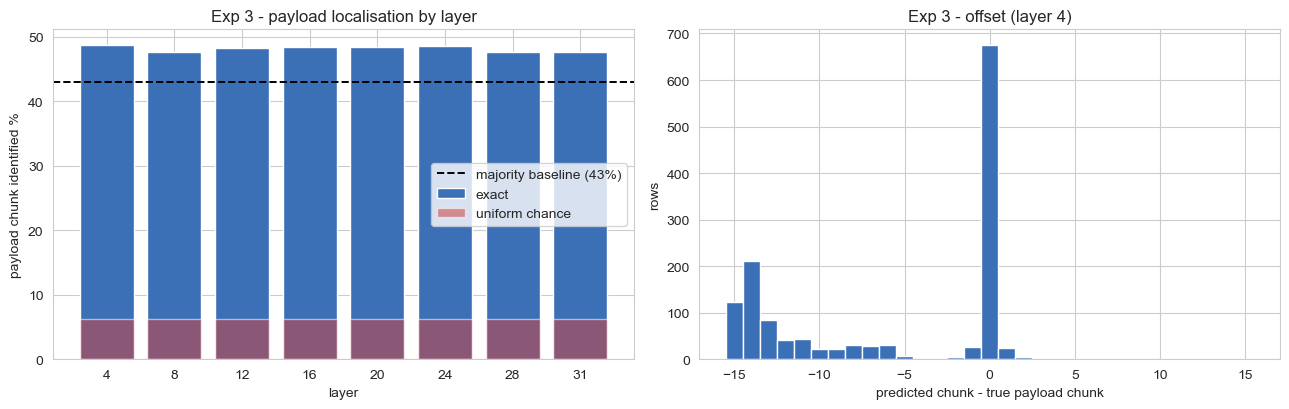

In [7]:
# ================= EXP 3 — localisation ======================================
# Does the flagged chunk contain the payload? Ground truth from span_start.
# This is the one result a better classifier cannot manufacture.
rows, y, oof, _ = grouped_cv(mask=inj_mask | clean_mask, arm="v15_position")
inj_rows = rows[y == 1]
gt = payload_chunk(inj_rows)
ok = gt >= 0

# Prototypes are GROUPED-OUT, not in-sample. Scoring a row against a prototype set that
# contains its own payload delta makes every row match itself and lands the argmax on the
# right chunk by construction -- a synthetic dry run on pure noise scored 100% exact that
# way. Exp 3 is the one result a better classifier cannot manufacture, so it must not be
# manufactured here either: for each fold, prototypes come only from OTHER payload groups,
# and the self column is masked as a second line of defence.
E3, PRED = {}, {}
PRED_ALL = {li: np.zeros(len(inj_rows), int) for li in LAYERS}
skf3 = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED)
for tr3, te3 in skf3.split(np.zeros(len(inj_rows)), np.ones(len(inj_rows), int),
                           groups=ev.payload_id.values[inj_rows]):
    pr, pc = delta_prototypes(inj_rows[tr3])
    for li in LAYERS:
        D = DL[li][inj_rows[te3]]
        P = DL[li][pr, pc] if len(pr) else np.zeros((1, D.shape[-1]), np.float32)
        S = _norm(D) @ _norm(P).T
        pos = {int(r): j for j, r in enumerate(pr)}
        for i_, r in enumerate(inj_rows[te3]):
            j = pos.get(int(r))
            if j is not None: S[i_, :, j] = -np.inf
        S = np.where(valid_delta_mask(NCH_EV[inj_rows[te3]]), S.max(axis=2), -np.inf)
        PRED_ALL[li][te3] = S.argmax(1)

for li in LAYERS:
    pred = PRED_ALL[li]
    PRED[li] = pred
    hit  = (pred[ok] == gt[ok]).mean() * 100
    near = (np.abs(pred[ok] - gt[ok]) <= 1).mean() * 100
    chance = float(np.mean(1.0 / np.maximum(1, NCH_EV[inj_rows][ok])) * 100)
    E3[li] = {"exact": float(hit), "within1": float(near), "chance": chance}
# Uniform chance is too soft a baseline here: BIPIA places the payload at start or end
# 50/50, so a detector that ALWAYS guesses the modal chunk already scores well. Report
# the majority-class baseline too -- beating uniform chance proves nothing.
vals, cnts = np.unique(gt[ok], return_counts=True)
MAJ = float(cnts.max() / cnts.sum() * 100)
for li in E3: E3[li]["majority_baseline"] = MAJ
print(f"  {'layer':>6}{'exact %':>10}{'within 1 %':>13}{'uniform %':>11}{'majority %':>12}{'vs maj':>9}")
print("  " + "-"*61)
for li, v in E3.items():
    print(f"  {li:>6}{v['exact']:>10.1f}{v['within1']:>13.1f}{v['chance']:>11.1f}"
          f"{v['majority_baseline']:>12.1f}{v['exact']-v['majority_baseline']:>+8.1f}")
print(f"\n  payload chunk distribution: {dict(zip(vals.tolist(), cnts.tolist()))}")
print("  Only 'vs maj' counts. BIPIA is 50/50 start/end by construction, so a")
print("  constant guess beats uniform chance without localising anything.")
print("  Prototypes are grouped-out by payload_id and self-masked -- an in-sample")
print("  prototype set scores 100% on pure noise, so this number would be meaningless.")
best_li = max(E3, key=lambda l: E3[l]["exact"])
print(f"\n  best layer {best_li}: {E3[best_li]['exact']:.1f}% exact "
      f"({E3[best_li]['exact']/max(E3[best_li]['chance'],1e-9):.1f}x chance)")
print("  v14's diagnostic said layer 4 carries ~3x the margin -- check whether")
print("  localisation agrees, and report the two together.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar([str(l) for l in E3], [E3[l]["exact"] for l in E3], color="#3b6fb6", label="exact")
ax[0].bar([str(l) for l in E3], [E3[l]["chance"] for l in E3], color="#c44", alpha=.55, label="uniform chance")
ax[0].axhline(MAJ, color="k", ls="--", lw=1.4, label=f"majority baseline ({MAJ:.0f}%)")
ax[0].set_xlabel("layer"); ax[0].set_ylabel("payload chunk identified %")
ax[0].set_title("Exp 3 - payload localisation by layer"); ax[0].legend()
off = PRED[best_li][ok] - gt[ok]
ax[1].hist(off, bins=np.arange(-MC, MC)+.5, color="#3b6fb6")
ax[1].set_xlabel("predicted chunk - true payload chunk"); ax[1].set_ylabel("rows")
ax[1].set_title(f"Exp 3 - offset (layer {best_li})")
plt.tight_layout(); plt.savefig(f"outputs/{FIG}_localisation.png", dpi=160)
plt.savefig(f"{RESULT_DIR}/{FIG}_localisation.png", dpi=160); plt.show()

In [8]:
# ================= EXP 4 — indirect leave-one-family-out =====================
# v14 run 2: BIPIA held out AUC 0.7031, InjecAgent 0.8042 (HGB, last-token features).
# A payload-shaped DELTA should transfer between carrier types if the mechanism is real.
FAMS = {"BIPIA": ["BIPIA", "BIPIA-Clean", "BIPIA-HardNeg"],
        "InjecAgent": ["InjecAgent", "InjecAgent-Clean", "InjecAgent-HardNeg"]}
E4 = {}
print(f"  {'arm':<16}{'held out':<13}{'n_inj':>7}{'AUC':>8}{'ASR % [95%]':>22}")
print("  " + "-"*66)
for arm in ["v14_lasttoken", "v15_position", "both"]:
    for held, cs in FAMS.items():
        hold = ev.corpus.isin(cs).values
        tr_rows = np.where(~hold & (inj_mask | clean_mask | hard_mask))[0]
        ytr = ev.label.values[tr_rows]
        proto = delta_prototypes(tr_rows)
        Xtr, nmz = features(tr_rows, proto)
        keep = np.array([FEATSET[arm](n) for n in nmz])
        sc = RobustScaler().fit(Xtr[:, keep])
        c = PRIMARY().fit(sc.transform(Xtr[:, keep]), ytr)
        ho_i = np.where(hold & inj_mask)[0]
        ho_b = np.where(hold & (clean_mask | hard_mask))[0]
        Xi, _ = features(ho_i, proto); Xb, _ = features(ho_b, proto)
        si = c.predict_proba(sc.transform(Xi[:, keep]))[:, 1]
        sb = c.predict_proba(sc.transform(Xb[:, keep]))[:, 1]
        pt = nested(si, sb)
        E4[f"{arm}|{held}"] = pt
        print(f"  {arm:<16}{held:<13}{len(ho_i):>7}{pt['auc']:>8.4f}{fmt(pt['asr']):>22}")
print("  " + "-"*66)
print("  v14 run 2 (last-token, full corpus): BIPIA 0.7031 / InjecAgent 0.8042")

  arm             held out       n_inj     AUC           ASR % [95%]
  ------------------------------------------------------------------
  v14_lasttoken   BIPIA           1200  0.6365   74.64 [72.42,77.84]
  v14_lasttoken   InjecAgent       186  0.8400   42.47 [37.63,46.77]
  v15_position    BIPIA           1200  0.5237   87.11 [84.75,89.09]
  v15_position    InjecAgent       186  0.5467   87.59 [86.01,88.71]
  both            BIPIA           1200  0.6081   76.62 [75.17,78.33]
  both            InjecAgent       186  0.8131   51.42 [45.70,56.45]
  ------------------------------------------------------------------
  v14 run 2 (last-token, full corpus): BIPIA 0.7031 / InjecAgent 0.8042


In [9]:
# ---- persist ---------------------------------------------------------------
strip = lambda d: {k: v for k, v in d.items() if k not in ("oof", "rows")}
out = dict(version="v15", run_at=pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
           pca_components=int(N_PCA), chunking="proportional",
           min_chunk_tok=int(MIN_CHUNK_TOK), max_chunks=int(MC),
           min_chunks=int(MIN_CHUNKS), seed=SEED, classifier="HistGradientBoost",
           rows=int(len(ev)), payload_groups=int(ev.payload_id.nunique()),
           exp1_ablation={k: strip(v) for k, v in E1.items()},
           exp2_threshold_spread=E2, exp3_localisation=E3,
           exp4_indirect_loco=E4)
json.dump(out, open(f"{RESULT_DIR}/metrics.json", "w"), indent=2)

oo = pd.DataFrame({"score": E1["both"]["oof"],
                   "label": ev.label.values[np.array(E1["both"]["rows"])],
                   "corpus": ev.corpus.values[np.array(E1["both"]["rows"])],
                   "pair_id": ev.pair_id.values[np.array(E1["both"]["rows"])],
                   "payload_id": ev.payload_id.values[np.array(E1["both"]["rows"])]})
oo.to_csv(f"{RESULT_DIR}/oof_v15.csv", index=False)

print(f"wrote {RESULT_DIR}/metrics.json + oof_v15.csv")
print("\n--- verdict ---")
b  = E1["both"]
bc = b["per_carrier"]
hit = (bc["asr"][0] < TARGET_ASR) and all(v < TARGET_FPR for v in b["by_corpus_fpr"].values())
print(f"  per-carrier ASR {bc['asr'][0]:.2f}% [{bc['asr_binom'][0]:.2f},{bc['asr_binom'][1]:.2f}]"
      f" | tier-1 FPR {bc['fpr'][0]:.2f}% | tier-2 FPR {bc['cross']['hardneg'][0]:.2f}%")
print(f"  (row-level, for continuity with v14: ASR {b['asr'][0]:.2f}% FPR {b['fpr'][0]:.2f}%)")
print(f"  worst tier-1 corpus FPR {max(b['by_corpus_fpr'].values()):.2f}%")
print(f"  TARGET (ASR<{TARGET_ASR}, all tier-1 FPR<{TARGET_FPR}): {'MET' if hit else 'not met'}")
print(f"  threshold spread {E2['both']['spread']:.3g}x  (v14: 7.5e3x)")
print(f"  localisation best layer {best_li}: {E3[best_li]['exact']:.1f}% exact")
print("\nUpdate versions/14_mslsam-v15/README.md, EXPERIMENTS.md and AGENTS.md (R2/R3/R5).")

wrote results/v15/metrics.json + oof_v15.csv

--- verdict ---
  per-carrier ASR 66.86% [62.62,70.86] | tier-1 FPR 10.12% | tier-2 FPR 28.24%
  (row-level, for continuity with v14: ASR 29.25% FPR 10.08%)
  worst tier-1 corpus FPR 19.79%
  TARGET (ASR<5.0, all tier-1 FPR<10.0): not met
  threshold spread 24.5x  (v14: 7.5e3x)
  localisation best layer 4: 48.7% exact

Update versions/14_mslsam-v15/README.md, EXPERIMENTS.md and AGENTS.md (R2/R3/R5).
